# Extension: where the windmills stand
### Real wind and biodiversity data, joined to the individual wind farms (≈ 30 min)

The main exercise treats Poland's offshore wind as one aggregate stock *w* with an *assumed* capacity factor of 0.45 and one passive-use exponent *u*₃. But wind farms are places. Here we replace both with **geographically distributed data**, evaluated at each farm:

| Layer | Source | Becomes in the model |
|---|---|---|
| Hourly 100 m wind 2020–2024 | ERA5 reanalysis via the Open-Meteo archive API | site capacity factor → wind revenue *p*<sub>e</sub> |
| Marine Natura 2000 sites | EMODnet Human Activities `natura2000areas` | distance to protected sites → sensitivity |
| Sightings of species sensitive to offshore wind (long-tailed duck, common and velvet scoter, red-throated diver, harbour porpoise) | OBIS | records near the farm → sensitivity |
| Distance to coast | EMODnet `windfarms` | investment cost per GW *p*<sub>I</sub> |

Then the question every marine spatial planner faces: **same 9.3 GW, same timing — but which sites?**

| Time | Part |
|---|---|
| 0–2 min | 0. Setup (loads the calibrated model of the main notebook) |
| 2–12 | 1. Real wind → capacity factor per farm |
| 12–20 | 2. Biodiversity → sensitivity per farm |
| 20–30 | 3. Siting: three portfolios through the SES model |

## 0. Setup
`ses_model.py` contains the model and the Baltic calibration of the main notebook (parts 1 and 3), so we start from the same parameters.

`LIVE = False` by default: Open-Meteo allows only a few heavy requests per minute **per IP address**, and a training room shares one address. The bundled snapshot was fetched from the same services on 26 Oct 2026. Try `LIVE = True` at home.

In [1]:
import json, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.path import Path as MplPath
from ses_model import calibrate, simulate, present_values, DATA

LIVE = False
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

cal = calibrate()
P0, ices_rule, Iw_contracted = cal["P"], cal["ices_rule"], cal["Iw_contracted"]
base = present_values(simulate(P0, ices_rule, Iw_contracted, start_year=2025), P0, terminal=True)
print("Main notebook S1 (contracted wind, ICES rule), EUR m:", base.round(0).to_dict())

farms = pd.read_csv(DATA / "emodnet_windfarms_poland_2026-10-26.csv")
farms["dist_coast_km"] = farms.dist_coast_m / 1000
print(len(farms), "Polish wind farm sites from EMODnet,", round(farms.power_mw.sum() / 1000, 1), "GW")

Main notebook S1 (contracted wind, ICES rule), EUR m: {'bf': 594.0, 'bw': -118.0, 'bp': 1219.0, 'B': 1695.0}
26 Polish wind farm sites from EMODnet, 20.9 GW


## 1. Real wind → capacity factor per farm (10 min)

### 1a. Wind speed distributions from ERA5
For every farm and for a 0.25° grid over the Polish Baltic we use five years of hourly wind speed at 100 m (hub height of today's turbines is ~140 m; 100 m is the closest ERA5 level). We keep the **distribution** — hours per 1 m/s bin — because power is a strongly non-linear function of wind speed: the average wind alone gives the wrong answer.

Wind: bundled ERA5 snapshot (2020-2024, fetched 26 Oct 2026)


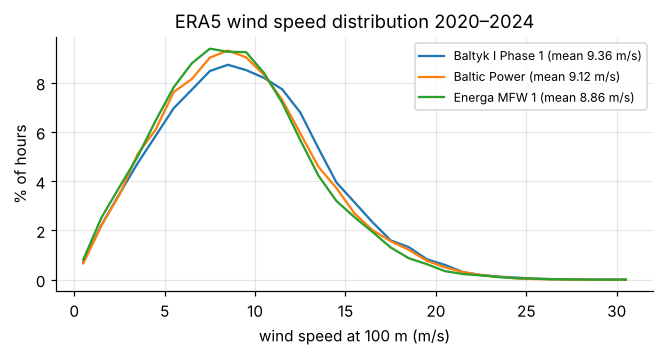

In [2]:
OM = "https://archive-api.open-meteo.com/v1/archive"

def hist_from_speeds(v):
    v = np.asarray([s for s in v if s is not None], float)
    return np.bincount(np.minimum(v.astype(int), 30), minlength=31), v.mean(), len(v)

def load_wind(live=LIVE):
    snap = pd.read_csv(DATA / "era5_wind100m_hist_2020-2024.csv")
    snap["hist"] = [np.array(s.split(), dtype=int) for s in snap.hist_0_30]
    if not live:
        print("Wind: bundled ERA5 snapshot (2020-2024, fetched 26 Oct 2026)")
        return snap
    import requests                                   # live: farms only (the grid stays from the snapshot)
    rows = []
    for i in range(0, len(farms), 13):
        ch = farms.iloc[i:i + 13]
        prm = {"latitude": ",".join(map(str, ch.lat)), "longitude": ",".join(map(str, ch.lon)),
               "start_date": "2020-01-01", "end_date": "2024-12-31", "hourly": "wind_speed_100m", "wind_speed_unit": "ms"}
        for attempt in range(2):
            r = requests.get(OM, params=prm, timeout=120)
            if r.status_code != 429: break
            print("Open-Meteo rate limit - waiting 61 s"); time.sleep(61)
        js = r.json(); js = js if isinstance(js, list) else [js]
        for (_, f), d in zip(ch.iterrows(), js):
            h, m, n = hist_from_speeds(d["hourly"]["wind_speed_100m"])
            rows.append(dict(kind="F", name=f["name"], lon=f.lon, lat=f.lat, mean_ws100=m, n_hours=n, hist=h))
        time.sleep(2)
    print("Wind: live Open-Meteo ERA5 for", len(rows), "farms; grid from snapshot")
    return pd.concat([pd.DataFrame(rows), snap[snap.kind == "G"]], ignore_index=True)

wind = load_wind()
fw = wind[wind.kind == "F"].set_index("name")
plt.figure(figsize=(7, 3))
for n in ["Baltyk I Phase 1", "Baltic Power", "Energa MFW 1 Offshore wind farm 1"]:
    h = fw.loc[n, "hist"]; plt.plot(np.arange(31) + .5, h / h.sum() * 100, label=f"{n.replace(' Offshore wind farm 1','')} (mean {fw.loc[n,'mean_ws100']:.2f} m/s)")
plt.xlabel("wind speed at 100 m (m/s)"); plt.ylabel("% of hours"); plt.legend(fontsize=8); plt.title("ERA5 wind speed distribution 2020–2024"); plt.show()

### 1b. From wind to electricity: a power curve
A generic 15 MW turbine: no output below 3 m/s (cut-in), output rising with the cube of wind speed up to rated power at 10.6 m/s, full power up to 25 m/s (cut-out). **Losses** (wakes inside large clusters, availability, cables) are an assumption: 15 %.

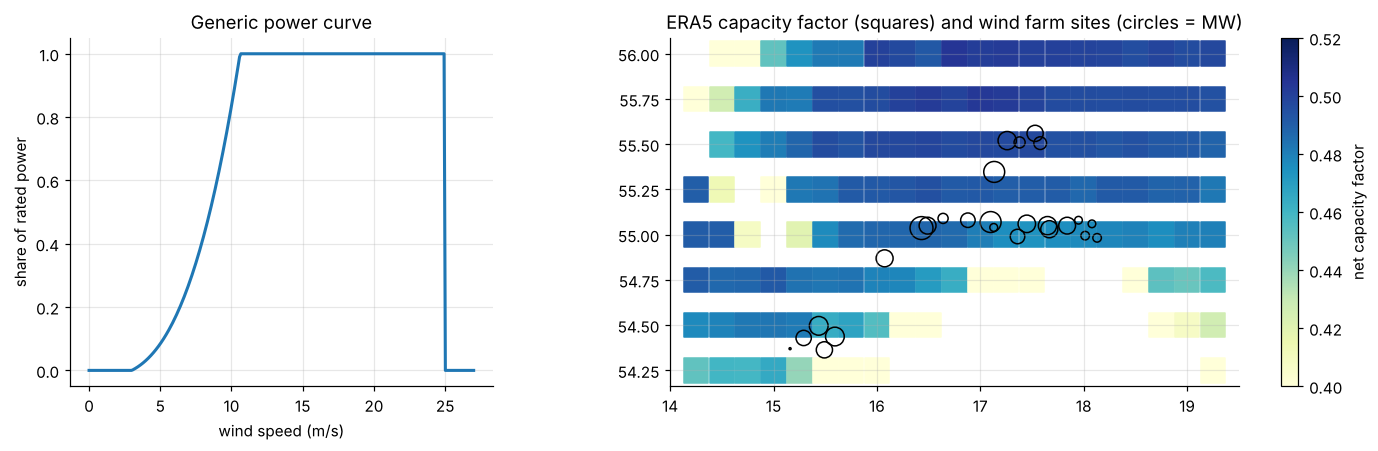

,name,power_mw,mean_ws100,cf,dist_coast_km
2,Baltyk I Phase 2,420.0,9.38,0.498,57.896
3,Baltica 1,900.0,9.37,0.498,68.611
1,Baltyk I Phase 1,1140.0,9.36,0.497,51.081
20,Baltica V Offshore wind farm 1,555.0,9.36,0.496,69.939
22,Freeboard I Offshore wind farm 1,1500.0,9.23,0.489,39.859
8,FEW Baltic II,350.0,9.23,0.488,30.662
9,Sharco Duo Offshore wind farm,1800.0,9.23,0.488,35.621
24,Baltica 9,975.0,9.23,0.488,33.843
6,Baltyk II,720.0,9.23,0.487,38.795
4,Baltica 2,1498.0,9.23,0.487,38.842


In [3]:
CUT_IN, RATED, CUT_OUT = 3.0, 10.6, 25.0          # ASSUMPTION: generic 15 MW turbine
LOSSES = 0.15                                      # ASSUMPTION: wake + availability + electrical

def power_curve(v):
    return np.where(v < CUT_IN, 0, np.where(v < RATED, (v**3 - CUT_IN**3) / (RATED**3 - CUT_IN**3), np.where(v <= CUT_OUT, 1, 0)))

def capacity_factor(hist):
    v = np.arange(31) + 0.5
    return (hist * power_curve(v)).sum() / hist.sum() * (1 - LOSSES)

wind["cf"] = wind["hist"].apply(capacity_factor)
farms = farms.drop(columns=["mean_ws100", "cf"], errors="ignore").merge(wind[wind.kind == "F"][["name", "mean_ws100", "cf"]], on="name", how="left")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 2]})
vv = np.linspace(0, 27, 300); ax[0].plot(vv, power_curve(vv), lw=2)
ax[0].set_xlabel("wind speed (m/s)"); ax[0].set_ylabel("share of rated power"); ax[0].set_title("Generic power curve")
g = wind[wind.kind == "G"]
sc = ax[1].scatter(g.lon, g.lat, c=g.cf, cmap="YlGnBu", marker="s", s=260, vmin=.40, vmax=.52)
ax[1].scatter(farms.lon, farms.lat, s=farms.power_mw / 8, facecolor="none", edgecolor="k", lw=1)
plt.colorbar(sc, ax=ax[1], label="net capacity factor"); ax[1].set_aspect(1.75)
ax[1].set_title("ERA5 capacity factor (squares) and wind farm sites (circles = MW)"); plt.tight_layout(); plt.show()
farms[["name", "power_mw", "mean_ws100", "cf", "dist_coast_km"]].sort_values("cf", ascending=False).round(3)

> **Discuss.** Offshore, the wind is remarkably uniform: all farm sites fall within a few percentage points of capacity factor. The low values in some coastal squares are ERA5 cells that partly cover land or lagoons. Farther offshore is slightly windier, but also farther from the grid connection.

### 1c. Back into the model: data instead of assumption

In [4]:
contracted_sites = {   # national project (main notebook) -> EMODnet site names
    "MFW Baltic Power": ["Baltic Power"], "Baltica 2": ["Baltica 2"], "Baltyk 2 + Baltyk 3": ["Baltyk II", "Baltyk III"],
    "BC-Wind": ["BC Wind Offshore wind farm C", "BC Wind Offshore wind farm B"], "Baltica 3": ["Baltica 3"],
    "MFW Baltyk 1": ["Baltyk I Phase 1", "Baltyk I Phase 2"], "Baltica 9+": ["Baltica 9", "FEW Baltic II"],
    "Baltic East": ["Baltic East"]}
farms["contracted"] = farms.name.isin(sum(contracted_sites.values(), []))

def wavg(df, col): return np.average(df[col], weights=df.power_mw)
price = cal["price_eur_mwh"]
cf_c = wavg(farms[farms.contracted], "cf")
pe_data = price * 8760 * cf_c * 1000 / 1e6
print(f"Contracted sites: {farms.contracted.sum()} EMODnet sites, {farms[farms.contracted].power_mw.sum()/1000:.2f} GW "
      "(EMODnet's capacities; national reporting says 9.33 GW)")
print(f"capacity-weighted CF from ERA5 = {cf_c:.3f}   (main notebook assumed 0.45)")
print(f"wind revenue per GW: {P0['pe']:.0f} -> {pe_data:.0f} EUR m/yr")

Contracted sites: 12 EMODnet sites, 9.47 GW (EMODnet's capacities; national reporting says 9.33 GW)
capacity-weighted CF from ERA5 = 0.484   (main notebook assumed 0.45)
wind revenue per GW: 453 -> 488 EUR m/yr


## 2. Biodiversity → sensitivity per farm (8 min)

Two complementary layers:
* **Natura 2000** — where the EU *designated* protection (Ławica Słupska, for example, is both a bird SPA and a habitat SCI). Authoritative, but binary.
* **OBIS occurrence records** of species known to be sensitive to offshore wind: seaducks and divers avoid turbines (displacement), harbour porpoises are disturbed by pile-driving noise. Rich, but records show where people *looked*, not only where animals *are*.

In [5]:
SPECIES = ["Clangula hyemalis", "Melanitta fusca", "Melanitta nigra", "Gavia stellata", "Phocoena phocoena"]

def load_biodiversity(live=LIVE):
    if live:
        try:
            import requests
            geom = "POLYGON((14 54,19.5 54,19.5 56.1,14 56.1,14 54))"; rows = []
            for s in SPECIES:
                after = None
                while True:
                    prm = {"scientificname": s, "geometry": geom, "size": 10000, "fields": "id,decimalLongitude,decimalLatitude,individualCount,date_year"}
                    if after: prm["after"] = after
                    res = requests.get("https://api.obis.org/v3/occurrence", params=prm, timeout=120).json()["results"]
                    rows += [dict(species=s, lon=r["decimalLongitude"], lat=r["decimalLatitude"]) for r in res]
                    if len(res) < 10000: break
                    after = res[-1]["id"]
            o = pd.DataFrame(rows)
            o["lon"] = 14.25 + 0.25 * np.round((o.lon - 14.25) / 0.25); o["lat"] = 54.25 + 0.25 * np.round((o.lat - 54.25) / 0.25)
            obis = o.groupby(["species", "lon", "lat"]).size().rename("n_records").reset_index()
            prm = {"service": "WFS", "version": "2.0.0", "request": "GetFeature", "typeNames": "emodnet:natura2000areas",
                   "outputFormat": "application/json", "srsName": "EPSG:4326", "CQL_FILTER": "ms='PL' AND mar_perc>=95"}
            n2k = requests.get("https://ows.emodnet-humanactivities.eu/wfs", params=prm, timeout=120).json()
            print("Biodiversity: live OBIS +", len(n2k["features"]), "Natura 2000 sites from EMODnet")
            return obis, n2k
        except Exception as e:
            print("live call failed -> snapshot.", type(e).__name__, e)
    obis = pd.read_csv(DATA / "obis_sensitive_species_grid025_2026-10-26.csv")
    n2k = json.load(open(DATA / "emodnet_natura2000_PL_marine_2026-10-26.geojson", encoding="utf-8"))
    print("Biodiversity: bundled snapshot (OBIS + EMODnet Natura 2000, 26 Oct 2026)")
    return obis, n2k

obis, n2k = load_biodiversity()
obis.groupby("species").n_records.sum()

Biodiversity: bundled snapshot (OBIS + EMODnet Natura 2000, 26 Oct 2026)


species
Clangula hyemalis    17250
Gavia stellata         373
Melanitta fusca      10149
Melanitta nigra      14891
Phocoena phocoena     2908
Name: n_records, dtype: int64

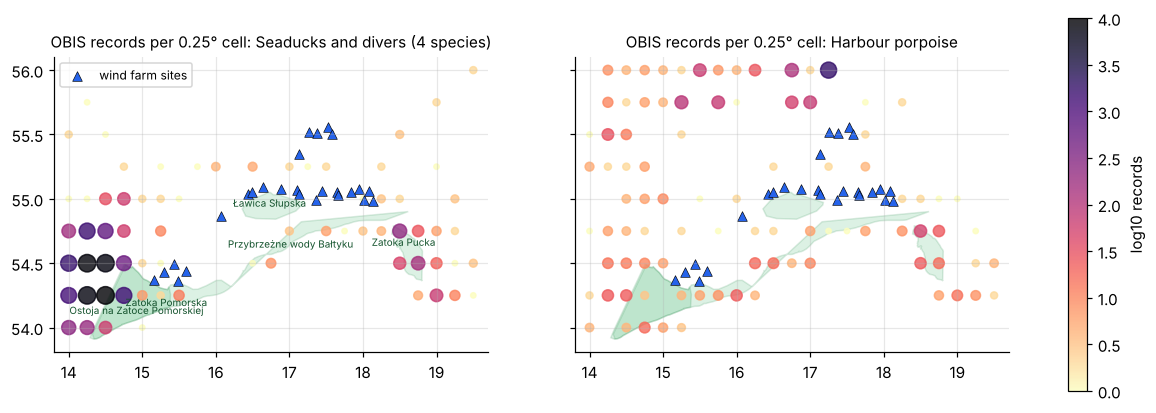

In [6]:
def draw_n2k(ax, label=True):
    for f in n2k["features"]:
        for poly in f["geometry"]["coordinates"]:
            r = np.array(poly[0]); ax.fill(r[:, 0], r[:, 1], fc="#16a34a", alpha=.15, ec="#15803d", lw=1)
        if label:
            r = np.array(max((p[0] for p in f["geometry"]["coordinates"]), key=len))
            ax.text(r[:, 0].mean(), r[:, 1].mean(), f["properties"]["sitename"], fontsize=6.5, color="#14532d", ha="center")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for a, sel, title in [(ax[0], obis.species != "Phocoena phocoena", "Seaducks and divers (4 species)"),
                      (ax[1], obis.species == "Phocoena phocoena", "Harbour porpoise")]:
    c = obis[sel].groupby(["lon", "lat"]).n_records.sum().reset_index()
    draw_n2k(a, label=a is ax[0])
    sc = a.scatter(c.lon, c.lat, s=12 + 30 * np.log10(c.n_records), c=np.log10(c.n_records), cmap="magma_r", alpha=.8, vmin=0, vmax=4)
    a.scatter(farms.lon, farms.lat, marker="^", s=40, c="#2563eb", edgecolor="k", lw=.4, label="wind farm sites")
    a.set_title(f"OBIS records per 0.25° cell: {title}", fontsize=10); a.set_aspect(1.75); a.set_xlim(13.8, 19.7)
plt.colorbar(sc, ax=ax, label="log10 records"); ax[0].legend(fontsize=8, loc="upper left"); plt.show()

> **Discuss — sampling bias.** Nearly all seaduck records come from the Pomeranian Bay (west), where long-running survey programmes report to OBIS. Ławica Słupska is a designated bird area of international importance, yet OBIS holds almost no records there. *No records ≠ no birds.* This is why we combine OBIS with the Natura 2000 designations rather than trusting either alone.

### 2b. A sensitivity index per farm
$$S_i = w_N\, e^{-d_i/10\,\mathrm{km}} + (1-w_N)\, \frac{\log(1+r_i)}{\max_j \log(1+r_j)}$$
with $d_i$ the distance to the nearest marine Natura 2000 site (0 inside) and $r_i$ the OBIS records of the five species in the farm's cell and its 8 neighbours (≈ 50 × 50 km). The weight $w_N$ = 0.6 is an **assumption**: designation counts a bit more than records.

In [7]:
W_N2K, DECAY_KM = 0.6, 10.0                        # ASSUMPTIONS

def to_km(lon, lat, lon0=17.0, lat0=55.0):
    return np.c_[(np.asarray(lon) - lon0) * 111.32 * np.cos(np.radians(lat0)), (np.asarray(lat) - lat0) * 110.57]

def dist_to_ring(lon, lat, ring):
    r = to_km(*np.array(ring).T); p = to_km(lon, lat)[0]
    if MplPath(r).contains_point(p): return 0.0
    a, b = r[:-1], r[1:]; ab = b - a
    t = np.clip(((p - a) * ab).sum(1) / np.maximum((ab * ab).sum(1), 1e-12), 0, 1)
    return np.hypot(*(a + t[:, None] * ab - p).T).min()

def nearest_n2k(lon, lat):
    best = min(((dist_to_ring(lon, lat, poly[0]), f["properties"]["sitename"]) for f in n2k["features"]
                for poly in f["geometry"]["coordinates"]), key=lambda z: z[0])
    return best

cells = obis.groupby(["lon", "lat"]).n_records.sum()
def records_near(lon, lat, r=0.25):
    lo, la = cells.index.get_level_values(0), cells.index.get_level_values(1)
    return int(cells[(abs(lo - lon) <= r + 1e-6) & (abs(la - lat) <= r + 1e-6)].sum())

near = [nearest_n2k(a, b) for a, b in zip(farms.lon, farms.lat)]
farms["d_n2k_km"] = [float(d) for d, _ in near]
farms["nearest_n2k"] = [n for _, n in near]
farms["obis_records"] = [records_near(a, b) for a, b in zip(farms.lon, farms.lat)]
lr = np.log1p(farms.obis_records)
farms["S"] = W_N2K * np.exp(-farms.d_n2k_km / DECAY_KM) + (1 - W_N2K) * lr / lr.max()
farms[["name", "power_mw", "d_n2k_km", "nearest_n2k", "obis_records", "S", "contracted"]].sort_values("S", ascending=False).round(2)

,name,power_mw,d_n2k_km,nearest_n2k,obis_records,S,contracted
23,Energa MFW 1 Offshore wind farm 1,900.0,2.62,Zatoka Pomorska,25,0.86,False
15,Licence Application No. 76,14.0,3.34,Zatoka Pomorska,22,0.81,False
24,Baltica 9,975.0,5.56,Ławica Słupska,7,0.60,True
9,Sharco Duo Offshore wind farm,1800.0,5.57,Ławica Słupska,7,0.60,False
21,Orlen Neptun IV Offshore wind farm 1,1200.0,11.49,Zatoka Pomorska,26,0.59,False
8,FEW Baltic II,350.0,5.91,Ławica Słupska,7,0.58,True
18,Energa MFW 2 Offshore wind farm 1,800.0,12.39,Zatoka Pomorska,25,0.57,False
11,BC Wind Offshore wind farm B,250.0,11.89,Przybrzeżne wody Bałtyku,21,0.56,True
12,Baltica 2+,210.0,6.24,Ławica Słupska,5,0.54,False
10,BC Wind Offshore wind farm C,250.0,13.90,Przybrzeżne wody Bałtyku,21,0.52,True


## 3. Siting: same 9.3 GW, same timing — which sites? (10 min)

Each site now has three numbers: **wind** (capacity factor), **cost** (farther from the coast means longer export cables and vessel trips: +0.4 % investment per km beyond 30 km — an **assumption**) and **sensitivity** *S*.

They enter the SES model as capacity-weighted averages over the chosen portfolio. Every portfolio has the contracted capacity (the last site picked may be used partly), and the model builds it on the same timeline as in the main notebook — only *where* changes:
* $p_e = \text{price} \times 8760\,\text{h} \times \overline{CF}$
* $p_I = p_I^{\text{Baltica 2}} \times \overline{(1 + 0.004\,(d_{\text{coast}} - 30))}$
* $u_3 = u_3^{\text{main}} \times \overline{S} / \overline{S}_{\text{contracted}}$ — the public's dislike of turbines scales with how sensitive their sites are, so the contracted portfolio reproduces the main notebook's *u*₃ = −0.05.

In [8]:
COST_PER_KM = 0.004                                # ASSUMPTION: +0.4 % capex per km beyond 30 km
farms["capex_factor"] = 1 + COST_PER_KM * (farms.dist_coast_km - 30)
S_ref = wavg(farms[farms.contracted], "S")
target_mw = farms[farms.contracted].power_mw.sum()

# a portfolio = MW used at each site (a Series over farms)
def pavg(mw, col): return np.average(farms[col], weights=mw)

def portfolio_params(mw, P=P0):
    return {**P, "pe": price * 8760 * pavg(mw, "cf") * 1000 / 1e6,
                 "Iwp": P["Iwp"] * pavg(mw, "capex_factor"),
                 "pu3": P["pu3"] * pavg(mw, "S") / S_ref}

def pick(score):
    '''Greedy: take the best-scoring sites until the contracted capacity is reached (last site partly).'''
    mw = pd.Series(0.0, index=farms.index)
    for i in score.sort_values(ascending=False).index:
        mw[i] = min(farms.loc[i, "power_mw"], target_mw - mw.sum())
        if mw.sum() >= target_mw - 1e-6: break
    return mw

z = lambda s: (s - s.mean()) / s.std()
LAMBDA = 1.0                                       # weight on sensitivity relative to wind and cost — change me
score_econ = z(farms.cf) - z(farms.capex_factor)
PORT = {"Contracted (actual)": farms.power_mw.where(farms.contracted, 0.0),
        "Best economics":      pick(score_econ),
        f"Economics + nature (λ = {LAMBDA})": pick(score_econ - LAMBDA * z(farms.S))}

rows = {}
for name, mw in PORT.items():
    Pp = portfolio_params(mw)
    pv = present_values(simulate(Pp, ices_rule, Iw_contracted, start_year=2025), Pp, terminal=True)
    rows[name] = {"GW": mw.sum() / 1000, "sites": int((mw > 0).sum()), "CF": pavg(mw, "cf"), "capex ×": pavg(mw, "capex_factor"),
                  "S": pavg(mw, "S"), "u3": Pp["pu3"], "PV fishery": pv.bf, "PV wind": pv.bw, "PV public": pv.bp, "PV total": pv.B}
rows["Main notebook S1 (assumed CF 0.45)"] = {"GW": target_mw / 1000, "sites": np.nan, "CF": 0.45, "capex ×": 1.0, "S": np.nan, "u3": P0["pu3"],
                                              "PV fishery": base.bf, "PV wind": base.bw, "PV public": base.bp, "PV total": base.B}
res = pd.DataFrame(rows).T
res.style.format({"GW": "{:.2f}", "sites": "{:.0f}", "CF": "{:.3f}", "capex ×": "{:.3f}", "S": "{:.2f}", "u3": "{:.3f}",
                  "PV fishery": "{:,.0f}", "PV wind": "{:,.0f}", "PV public": "{:,.0f}", "PV total": "{:,.0f}"})

,GW,sites,CF,capex ×,S,u3,PV fishery,PV wind,PV public,PV total
Contracted (actual),9.47,12,0.484,1.020,0.35,-0.050,594,"1,756","1,219","3,569"
Best economics,9.47,12,0.486,1.017,0.36,-0.051,594,"1,961","1,216","3,771"
Economics + nature (λ = 1.0),9.47,13,0.486,1.034,0.25,-0.035,594,"1,499","1,250","3,343"
Main notebook S1 (assumed CF 0.45),9.47,nan,0.450,1.000,nan,-0.050,594,-118,"1,219","1,695"


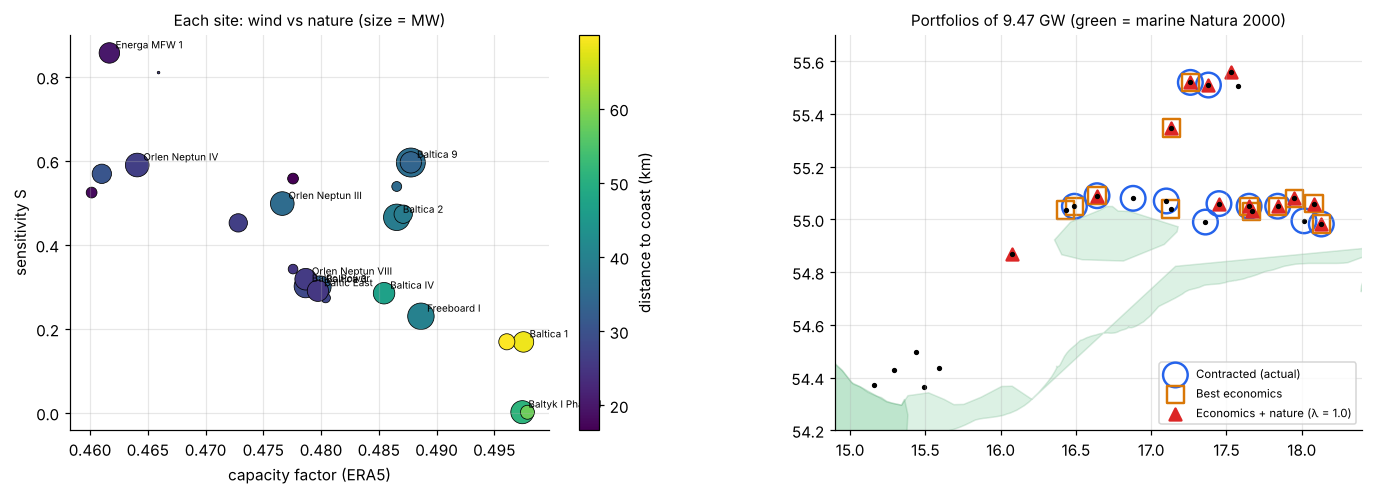

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
sc = ax[0].scatter(farms.cf, farms.S, s=farms.power_mw / 5, c=farms.dist_coast_km, cmap="viridis", edgecolor="k", lw=.5)
for _, r in farms[(farms.power_mw >= 900) & (farms.name != "Sharco Duo Offshore wind farm")].iterrows():
    ax[0].annotate(r["name"].replace(" Offshore wind farm 1", ""), (r.cf, r.S), fontsize=6.5, xytext=(4, 3), textcoords="offset points")
plt.colorbar(sc, ax=ax[0], label="distance to coast (km)")
ax[0].set_xlabel("capacity factor (ERA5)"); ax[0].set_ylabel("sensitivity S"); ax[0].set_title("Each site: wind vs nature (size = MW)", fontsize=10)

draw_n2k(ax[1], label=False)
mk = {"Contracted (actual)": ("o", "#2563eb", 260), "Best economics": ("s", "#d97706", 130)}
for name, mw in PORT.items():
    m, c, s = mk.get(name, ("^", "#dc2626", 60)); sel = mw > 0
    ax[1].scatter(farms[sel].lon, farms[sel].lat, marker=m, s=s, facecolor="none" if m != "^" else c, edgecolor=c, lw=1.6, label=name)
ax[1].scatter(farms.lon, farms.lat, s=6, c="k")
ax[1].set_aspect(1.75); ax[1].set_xlim(14.9, 18.4); ax[1].set_ylim(54.2, 55.7); ax[1].legend(fontsize=7.5, loc="lower right")
ax[1].set_title(f"Portfolios of {target_mw/1000:.2f} GW (green = marine Natura 2000)", fontsize=10); plt.tight_layout(); plt.show()

> **Read the results.**
> * Replacing the assumed capacity factor with ERA5 data changes the wind PV by thousands of EUR million — far more than any other change in this extension. *Measuring the resource is worth more than refining the model.*
> * The real (contracted) portfolio is already close to the "best economics" set: projects cluster on the windy, mid-distance Słupsk Bank area.
> * Adding nature to the score pushes the choice towards the distant northern sites (Bałtyk I, Baltica 1, Baltica V) and away from sites next to Ławica Słupska and the Pomeranian Bay. With *u*₃ = −0.05 the public-benefit gain is small compared with wind revenue — whether it is worth the higher capex depends entirely on how strongly the public values those species, which no dataset here tells us.

## Your turn
1. **How much does nature have to matter?** Raise `LAMBDA` to 3. Then make the public care more: in `portfolio_params` multiply `P["pu3"]` by 10. Does the nature-aware portfolio ever win on total PV? What does that say about the value the public would need to place on these sites?
2. **Engineering assumptions.** Set `LOSSES = 0.25` (big cluster wakes) or change the power curve (`RATED = 12`). How sensitive is the wind PV, and does the site ranking change?
3. **Trust in records.** Set `W_N2K = 0` (OBIS only) and then `1` (Natura 2000 only). Which farms change rank most, and why?
4. **Cost of distance.** Set `COST_PER_KM = 0`: which portfolio is "best economics" now?
5. **At home:** `LIVE = True` refetches wind for all farms from Open-Meteo, OBIS records and Natura 2000 from EMODnet.

## What this extension adds — and what it still assumes
| | Status |
|---|---|
| Wind resource per site (ERA5 2020–2024) | **DATA** — ERA5 tends to underestimate offshore wind slightly; hub height is above 100 m |
| Power curve, losses | **ASSUMPTION** — use the actual turbine model and wake modelling |
| Natura 2000 geometry | **DATA** (EMODnet, simplified outlines in the snapshot) |
| Species records | **DATA, biased** by survey effort — better: modelled density surfaces (e.g. seabird at-sea surveys, SAMBAH porpoise density) |
| Sensitivity weights, distance-cost factor, *u*₃ scaling | **ASSUMPTIONS** |
| Fishing displacement | not yet spatial — next step: overlay farm areas with ICES VMS fishing effort to set ε₂ per site |

### Sources
* ERA5 hourly 100 m wind via Open-Meteo Historical Weather API: https://open-meteo.com/en/docs/historical-weather-api (data: Copernicus Climate Change Service, ERA5)
* OBIS occurrence API: https://api.obis.org (records from the contributing datasets; cite OBIS and the datasets when publishing)
* EMODnet Human Activities, `natura2000areas` and `windfarms`: https://ows.emodnet-humanactivities.eu/wfs
* Main exercise and model: `baltic_ses_exercise.ipynb`, *Case-example II.xlsx*